# IMED Experiment 6 | October 30 refit

This notebook uses the October 30 refit for the PBM/QMOM diagnostics and the archived MATLAB comparison. Use the one-based experiment and model selectors to choose the detailed run. The diagnostic plots use the editable mesh. The MATLAB comparison uses the original mesh saved with the fit.

The API inventory includes solid mass tracked beyond the size mesh. Particle number, volume, and D-values describe the resolved crystals. The PBM plots remain available if QMOM stops.

In the saved Experiment 6 comparison, the largest final D-value error in Archived MATLAB PE mode is 0.00833 µm across both models.

In [1]:
from pathlib import Path
import sys

# Locate the IMED package when the kernel starts in notebooks/ or the workspace root.
cwd = Path.cwd().resolve()
root = next((folder for folder in (cwd, *cwd.parents)
             if (folder / "imed_python" / "solver.py").is_file()), None)
if root is None:
    raise RuntimeError("Open this notebook from the IMED workspace or its notebooks folder.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

from imed_python.distribution import cell_volumes, volume_distribution
from imed_python.solver import simulate
from imed_python.validation.qmom import solve_ccas_qmom

plt.rcParams.update({
    "figure.dpi": 125, "axes.grid": True, "grid.alpha": 0.26,
    "axes.spines.top": False, "axes.spines.right": False,
})

In [2]:
from imed_python.solver import read_model, model_parameters

path = (
    "C:/Users/abotondo/OneDrive - purdue.edu/Pfizer/2. Purdue Experiments/"
    "Evaluated expts/IMED_files/MD_refit_ACTUAL_D_values_RES_20261030.mat"
)

case = read_model(path)
experiment_number = 6
model_number = 2
experiment_index = experiment_number - 1
model_index = model_number - 1

experiment = case["ExpData"][experiment_index]
process = case["ProcInf"][experiment_index]
solubility = case["Solubility"]
settings = {**case["pbmsetting"], "Numerics": "conservative"}
parameters = model_parameters(case["ModelParameter"][model_index])

shape_factor = process["ShapeFactor"]
solid_density_g_cm3 = process["SolidDensity"]

settings["Lmax"] = 300

In [3]:
count, concentration, csd, state = simulate(parameters, experiment, process, solubility, settings,
                                return_history=True)
time = count[0]
qmom = None
try:
    qmom = solve_ccas_qmom(parameters, experiment, process, solubility, settings, time=time)
except (ValueError, RuntimeError, TimeoutError) as error:
    print(f"QMOM stopped: {error}")
    print("Plotting the completed PBM calculation.")

bins = settings["N"]
edges = np.linspace(settings["Lmin"], settings["Lmax"], bins + 1)
number_per_bin = state[:bins] * np.diff(edges)[:, None]
pbm_number = number_per_bin.sum(axis=0)
pbm_volume = cell_volumes(edges, shape_factor) @ number_per_bin / 1e12  # cm³
pbm_mean = np.divide(csd[0] @ number_per_bin, pbm_number,
                     out=np.full_like(pbm_number, np.nan), where=pbm_number > 0)

pbm_crystal = solid_density_g_cm3 * pbm_volume
pbm_dissolved = state[bins] * state[bins + 1]
pbm_resolved_total = pbm_crystal + pbm_dissolved
escaped = state[bins + 5]
pbm_total = pbm_resolved_total + escaped
inventory_error = np.max(np.abs(pbm_total - pbm_total[0]))
hours = time / 3600
print(f"PBM final concentration: {concentration[1, -1]:.6g} g/g solution")
print(f"Measured final concentration: {experiment['ConcentrationData'][1, -1]:.6g} g/g solution")
print(f"PBM final crystal mass inside mesh: {pbm_crystal[-1]:.4g} g")
print(f"Crystal mass transported beyond Lmax: {escaped[-1]:.4g} g")
print(f"Initial API inventory: {pbm_total[0]:.4g} g")
print(f"Max inventory residual with boundary flux: {inventory_error:.3g} g")
if qmom is not None:
    qmom_total = qmom.crystal_mass + qmom.dissolved_mass


PBM final concentration: 0.00292831 g/g solution
Measured final concentration: 0.00233476 g/g solution
PBM final crystal mass inside mesh: 20.56 g
Crystal mass transported beyond Lmax: 3.913e-05 g
Initial API inventory: 21.78 g
Max inventory residual with boundary flux: 1.06e-06 g


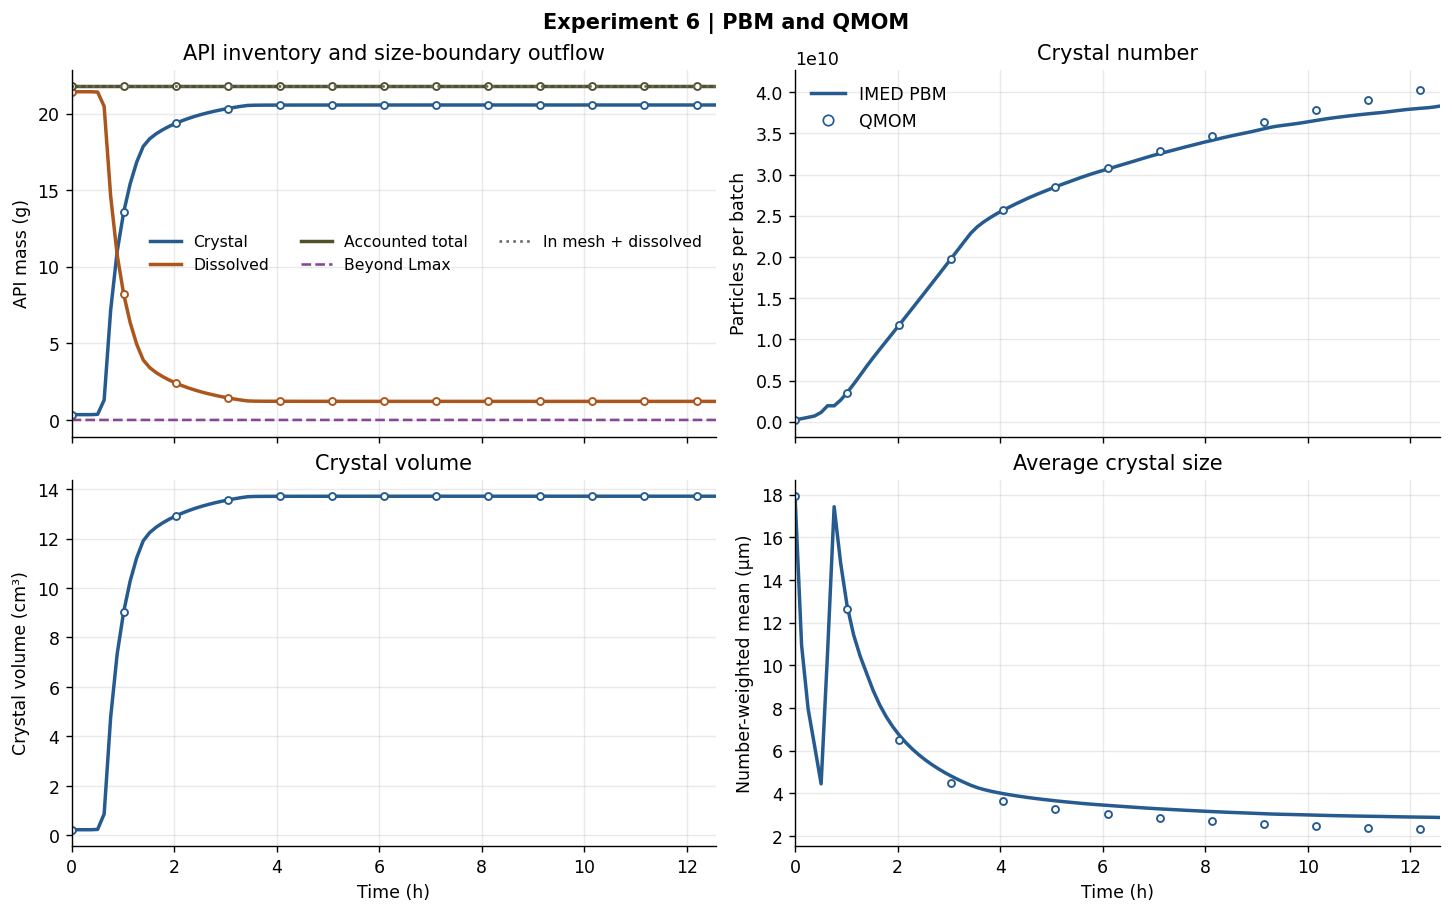

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.2), sharex=True, layout="constrained")
fig.suptitle(f"Experiment {experiment_number} | " + ("PBM and QMOM" if qmom is not None else "finite-volume PBM"),
             fontweight="bold")
palette = {"Crystal": "#265b90", "Dissolved": "#ab561d", "Accounted total": "#505129"}

def paired(ax, pbm, reference, color, label=None):
    ax.plot(hours, pbm, color=color, lw=2.0, label=label)
    if reference is None:
        return
    ax.plot(hours, reference, color=color, marker="o", markersize=4,
            markevery=8, markerfacecolor="white", markeredgewidth=1.1, lw=0)

for label, pbm, reference in [
    ("Crystal", pbm_crystal, (qmom.crystal_mass if qmom is not None else None)),
    ("Dissolved", pbm_dissolved, (qmom.dissolved_mass if qmom is not None else None)),
    ("Accounted total", pbm_total, (qmom_total if qmom is not None else None)),
]:
    paired(axes[0, 0], pbm, reference, palette[label], label)
axes[0, 0].plot(hours, escaped, color="#854894", ls="--", label="Beyond Lmax")
axes[0, 0].plot(hours, pbm_resolved_total, color="#676767", ls=":", label="In mesh + dissolved")
axes[0, 0].set(title="API inventory and size-boundary outflow", ylabel="API mass (g)")
axes[0, 0].legend(frameon=False, ncol=3, fontsize=9)

panels = [
    (axes[0, 1], pbm_number, (qmom.number if qmom is not None else None), "Crystal number", "Particles per batch"),
    (axes[1, 0], pbm_volume, (qmom.volume / 1e12 if qmom is not None else None), "Crystal volume", "Crystal volume (cm³)"),
    (axes[1, 1], pbm_mean, (qmom.mean_size if qmom is not None else None), "Average crystal size", "Number-weighted mean (µm)"),
    
]
for ax, pbm, reference, title, unit in panels:
    paired(ax, pbm, reference, palette["Crystal"])
    ax.set(title=title, ylabel=unit)
if qmom is not None:
    axes[0, 1].legend(handles=[
        Line2D([], [], color=palette["Crystal"], lw=2, label="IMED PBM"),
        Line2D([], [], color=palette["Crystal"], marker="o", markerfacecolor="white",
               lw=0, label="QMOM"),
    ], frameon=False)
for ax in axes[-1]:
    ax.set_xlabel("Time (h)")
axes[0, 0].set_xlim(hours[0], hours[-1])
plt.show()

## Operating conditions

The system volume combines the additive solvent and antisolvent volumes and resolved crystal volume. It excludes dissolved API partial volume and unresolved crystals. Equilibrium concentration uses the full MAT solubility model and the simulated antisolvent mass fraction.

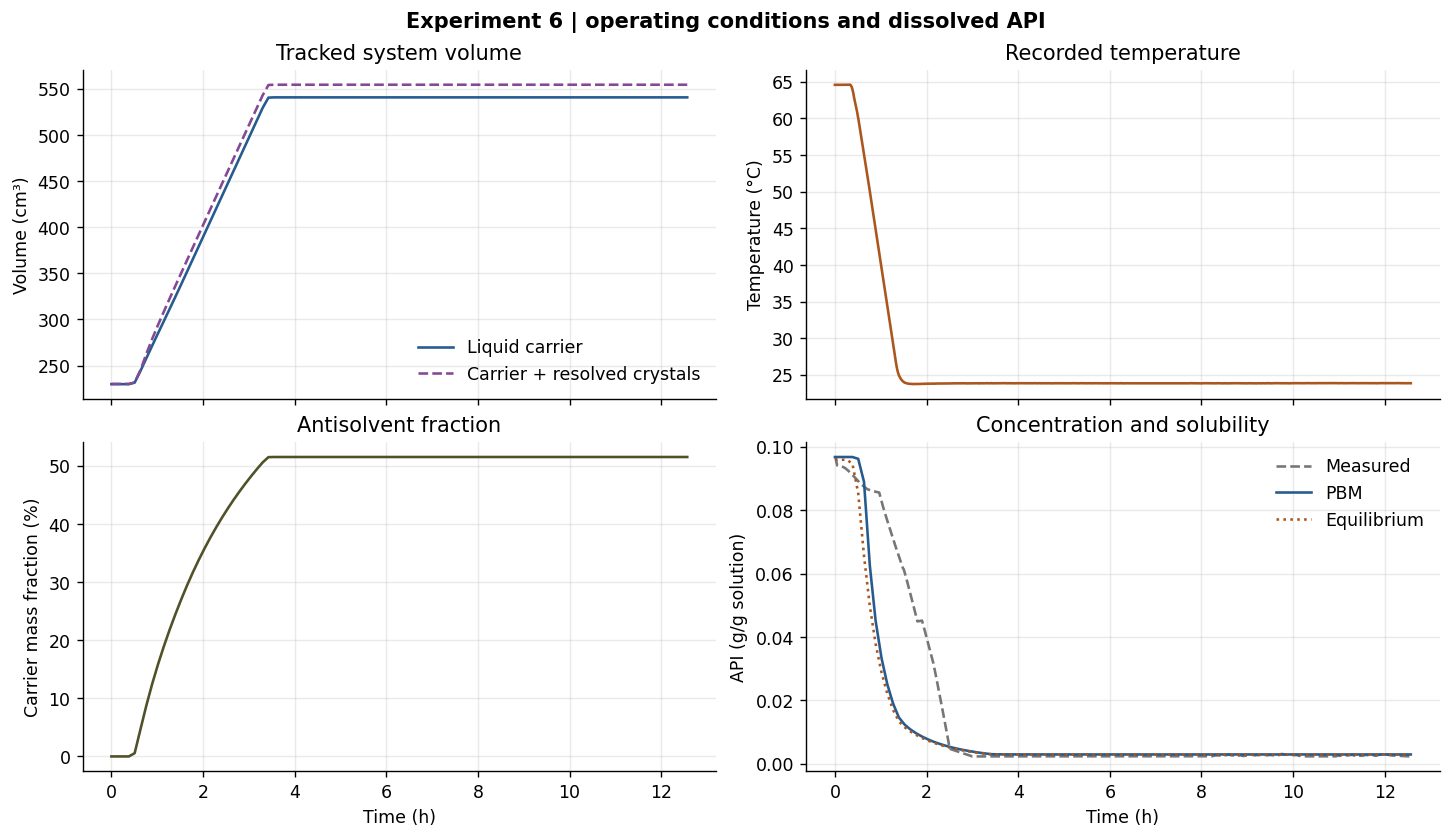

In [5]:
solvent = state[bins + 2]
anti = 1 - solvent
liquid_volume = state[bins + 1] * (solvent / process["SolventDensity"]
                                   + anti / process["AntiSolventDensity"])
recorded_temp = np.asarray(experiment["TemperatureData"])
temp_k = np.interp(time, *recorded_temp) + 273.15
a, b, c, d, e, f, g, h = (solubility[key] for key in "abcdefgh")
csat = np.exp(a + b / temp_k + c * np.log(temp_k) + d * anti + e * np.exp(anti)
              + f * anti**2 + g * anti / temp_k + h * np.exp(anti) / temp_k)

fig, axes = plt.subplots(2, 2, figsize=(11.5, 6.6), sharex=True, layout="constrained")
fig.suptitle(f"Experiment {experiment_number} | operating conditions and dissolved API", fontweight="bold")
axes[0, 0].plot(hours, liquid_volume, color="#265b90", label="Liquid carrier")
axes[0, 0].plot(hours, liquid_volume + pbm_volume, color="#854894", ls="--",
                label="Carrier + resolved crystals")
axes[0, 0].set(title="Tracked system volume", ylabel="Volume (cm³)")
axes[0, 0].legend(frameon=False)
axes[0, 1].plot(recorded_temp[0] / 3600, recorded_temp[1], color="#ab561d")
axes[0, 1].set(title="Recorded temperature", ylabel="Temperature (°C)")
axes[1, 0].plot(hours, 100 * anti, color="#505129")
axes[1, 0].set(title="Antisolvent fraction", ylabel="Carrier mass fraction (%)")
measured = experiment["ConcentrationData"]
axes[1, 1].plot(measured[0] / 3600, measured[1], color="#767676", ls="--", label="Measured")
axes[1, 1].plot(hours, concentration[1], color="#265b90", label="PBM")
axes[1, 1].plot(hours, csat, color="#ab561d", ls=":", label="Equilibrium")
axes[1, 1].set(title="Concentration and solubility", ylabel="API (g/g solution)")
axes[1, 1].legend(frameon=False)
for ax in axes[-1]:
    ax.set_xlabel("Time (h)")
plt.show()

## Resolved volume-weighted size

Open circles show the supplied seed and final measured percentiles. The October 30 archive supplies final measured D-values for these runs. Its final measured full distributions are empty. Each simulated distribution snapshot integrates to 100% of resolved crystal volume.

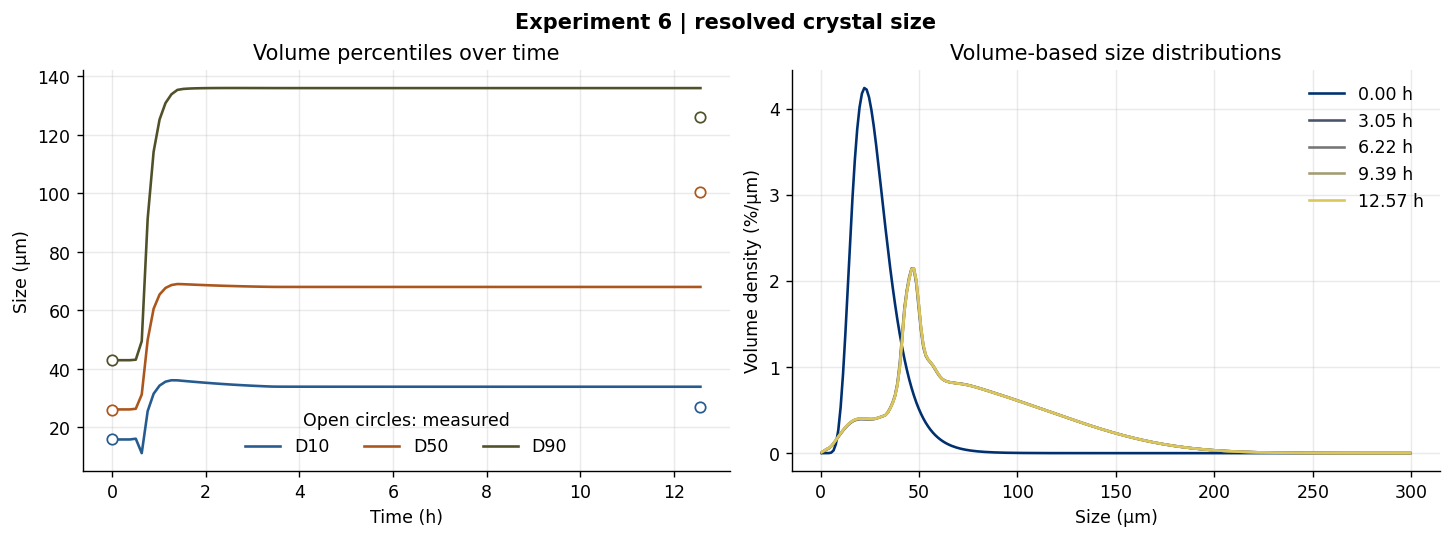

In [9]:
distributions = []
percentiles = np.full((3, time.size), np.nan)
for i, density in enumerate(state[:bins].T):
    curve, sizes = volume_distribution(np.vstack((csd[0], density)), process, settings)
    distributions.append(curve)
    if sizes is not None:
        percentiles[:, i] = sizes

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout="constrained")
fig.suptitle(f"Experiment {experiment_number} | resolved crystal size", fontweight="bold")
for i, (name, color) in enumerate(zip(("D10", "D50", "D90"), ("#265b90", "#ab561d", "#505129"))):
    axes[0].plot(hours, percentiles[i], color=color, label=name)
    for field, at in (("InitialD10D50D90", hours[0]), ("FinalD10D50D90", hours[-1])):
        values = np.asarray(experiment.get(field, []))
        if values.size == 3:
            axes[0].scatter(at, values[i], edgecolors=color, facecolors="white", zorder=5)
axes[0].set(title="Volume percentiles over time", xlabel="Time (h)", ylabel="Size (µm)")
axes[0].legend(frameon=False, ncol=3, title="Open circles: measured")
snapshots = np.linspace(0, time.size - 1, 5, dtype=int)
for i, color in zip(snapshots, plt.cm.cividis(np.linspace(0.08, 0.86, len(snapshots)))):
    axes[1].plot(*distributions[i], color=color, label=f"{hours[i]:.2f} h")
axes[1].set(title="Volume-based size distributions", xlabel="Size (µm)", ylabel="Volume density (%/µm)")
axes[1].legend(frameon=False)
plt.show()

## October 30 MATLAB comparison

Both Python modes run all six experiments with both fitted models from the October 30 archive. The saved weighted residuals recover MATLAB's peak-normalized count, concentration at observation times, and final D10/D50/D90. The table reports the worse error of the two models for each experiment and mode. The detailed plots use the selected experiment and model.

In [7]:
from contextlib import redirect_stdout
from io import StringIO

import pandas as pd
from IPython.display import display
from imed_python.validation.compare_matlab import compare

mode_names = {"conservative": "Conservative PBM", "matlab_pe": "Archived MATLAB PE"}
with redirect_stdout(StringIO()):
    rows, traces = compare(case, tuple(mode_names))
comparison = pd.DataFrame(rows)
trajectories = pd.DataFrame(traces)
completed = comparison["status"].eq("completed")
print(f"{completed.sum()} of {len(comparison)} Python runs completed.")
if not completed.all():
    display(comparison.loc[~completed, ["experiment", "model", "numerics", "status"]])

errors = comparison.copy()
errors["Count RMSE (% of peak)"] = 100 * errors["normalized_count_rmse"]
errors = errors.rename(columns={"concentration_rmse": "Concentration RMSE (g/g)",
                                "max_d_error_um": "Max D10/D50/D90 error (µm)"})
errors["Mode"] = errors["numerics"].map(mode_names)
metrics = ["Count RMSE (% of peak)", "Concentration RMSE (g/g)", "Max D10/D50/D90 error (µm)"]
display(errors.groupby(["experiment", "Mode"], sort=False)[metrics].max()
        .style.format("{:.4g}", na_rep="—"))

24 of 24 Python runs completed.


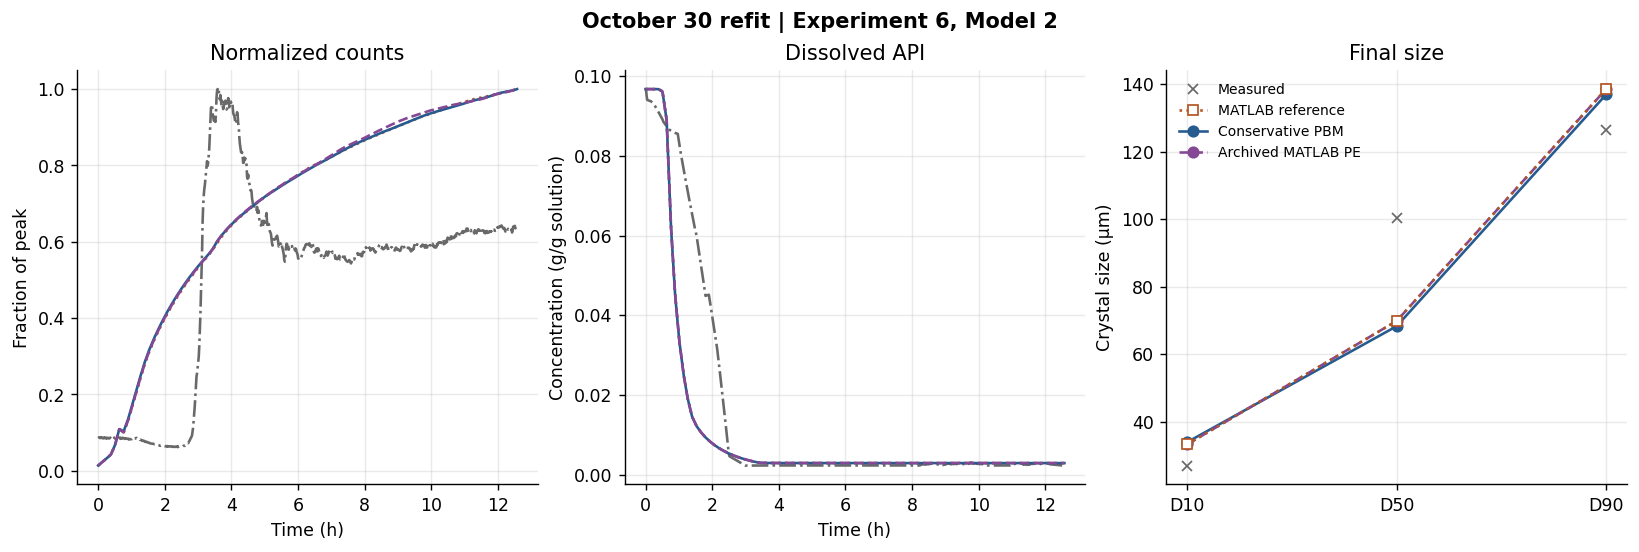

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), layout="constrained")
fig.suptitle(f"October 30 refit | Experiment {experiment_number}, Model {model_number}",
             fontweight="bold")
styles = {"Conservative PBM": ("#265b90", "-"), "Archived MATLAB PE": ("#854894", "--"),
          "MATLAB reference": ("#b45622", ":"), "Measured": ("#696969", "-.")}
selection = trajectories[(trajectories.experiment == experiment_number)
                         & (trajectories.model == model_number)]
results = comparison[(comparison.experiment == experiment_number)
                     & (comparison.model == model_number)]
for ax, channel, title, units in zip(axes[:2], ["count_normalized", "concentration"],
                                    ["Normalized counts", "Dissolved API"],
                                    ["Fraction of peak", "Concentration (g/g solution)"]):
    points = selection[selection.channel == channel]
    if points.empty:
        ax.set_title(title)
        ax.text(.5, .5, "No completed Python trace", ha="center", transform=ax.transAxes)
        continue
    first_mode = next(iter(points.groupby("numerics", sort=False)))[1]
    for field, label in (("measured", "Measured"), ("matlab", "MATLAB reference")):
        if first_mode[field].notna().any():
            color, line = styles[label]
            ax.plot(first_mode.time_s / 3600, first_mode[field], color=color, ls=line, label=label)
    for mode, trace in points.groupby("numerics", sort=False):
        label = mode_names[mode]
        color, line = styles[label]
        ax.plot(trace.time_s / 3600, trace.python, color=color, ls=line, label=label)
    ax.set(title=title, xlabel="Time (h)", ylabel=units)

ax = axes[-1]
d_values = [10, 50, 90]
for _, result in results.iterrows():
    label = mode_names[result.numerics]
    color, line = styles[label]
    ax.plot(d_values, [result.get(f"python_D{p}_um", np.nan) for p in d_values],
            color=color, ls=line, marker="o", label=label)
references = results.loc[results.matlab_reference & results.status.eq("completed")]
if not references.empty:
    reference = references.iloc[0]
    ax.plot(d_values, [reference.get(f"matlab_D{p}_um", np.nan) for p in d_values],
            color=styles["MATLAB reference"][0], ls=":", marker="s",
            markerfacecolor="white", label="MATLAB reference")
ax.plot(d_values, experiment["FinalD10D50D90"], color=styles["Measured"][0],
        ls="none", marker="x", label="Measured")
ax.set(title="Final size", ylabel="Crystal size (µm)")
ax.set_xticks(d_values, [f"D{p}" for p in d_values])
legend = {}
for ax in axes:
    handles, labels = ax.get_legend_handles_labels()
    legend.update(zip(labels, handles))
axes[-1].legend(legend.values(), legend.keys(), frameon=False, fontsize=8)
plt.show()